<a href="https://colab.research.google.com/github/abrandonwang/text-to-sound/blob/main/mel_vae.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/data
!cp /content/drive/MyDrive/text-to-sound/data/* /content/data/
!ls -lh /content/data

CKPT = "/content/drive/MyDrive/text-to-sound/checkpoints/"

Mounted at /content/drive
total 1.2G
-rw------- 1 root root 1.3M Nov  4 22:42 captions_dev.csv
-rw------- 1 root root  25M Nov  4 22:42 clap_audio.npy
-rw------- 1 root root 125M Nov  4 22:42 clap_text.npy
-rw------- 1 root root 995M Nov  4 22:42 mels.npy
-rw------- 1 root root  136 Nov  4 22:42 mel_stats.npy
-rw------- 1 root root 952K Nov  4 22:42 meta.csv


In [4]:
import torch
import glob
import pandas as pd
import os
from IPython.display import Audio, display
import librosa, librosa.display
import matplotlib.pyplot as plt
import numpy as np
import random
!test -d BigVGAN || git clone -q https://github.com/NVIDIA/BigVGAN
!sed -i 's/proxies: Optional\[Dict\],/proxies: Optional[Dict] = None,/; s/resume_download: bool,/resume_download: bool = False,/' BigVGAN/bigvgan.py
!grep -n "proxies\|resume_download" BigVGAN/bigvgan.py
import sys; sys.path.insert(0, "BigVGAN")
import torch, bigvgan
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
import torch.nn.functional as F
import math
import torch.nn as nn
from transformers import ClapModel, ClapProcessor
%matplotlib inline
device = "cuda"
vocoder = bigvgan.BigVGAN.from_pretrained("nvidia/bigvgan_v2_22khz_80band_256x", use_cuda_kernel = False)
vocoder.remove_weight_norm()
vocoder = vocoder.eval().to(device)
print(vocoder.h.sampling_rate)

# Updated path for Colab
DATA = "/content/data/"
mels = np.load(DATA + "mels.npy", mmap_mode = "r")
stats = np.load(DATA + "mel_stats.npy")
MIN, MAX = stats[0], stats[1]
meta = pd.read_csv(DATA + "meta.csv")

422:        proxies: Optional[Dict] = None,
423:        resume_download: bool = False,
444:                proxies=proxies,
445:                resume_download=resume_download,
476:                proxies=proxies,
477:                resume_download=resume_download,
Loading weights from nvidia/bigvgan_v2_22khz_80band_256x
Removing weight norm...
22050


In [5]:
class MelDataset(Dataset):
    def __init__(self, split):
        self.rows = meta.index[meta["split"] == split].to_numpy()
        self.audio = np.load(DATA + "clap_audio.npy")
        self.mels = np.load(DATA + "mels.npy")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows[i]
        mel = torch.tensor(self.mels[row].astype("float32"))
        clap = torch.tensor(self.audio[row].astype("float32"))
        clap = F.normalize(clap, dim = 0)
        return mel, clap

train_data = MelDataset("train")
loader = DataLoader(train_data, batch_size = 32, shuffle = True, num_workers = 2)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

In [6]:
mel, clap = next(iter(loader))
m = mel[0]
m = ((m + 1) / 2) * (MAX - MIN) + MIN
m = m.to(device)

with torch.inference_mode():
    wav = vocoder(m)
wav = wav.squeeze().cpu().numpy()
Audio(wav, rate = 22050)

In [28]:
class Autoencoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder = nn.Sequential(
      nn.Conv2d(1, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 64, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(64, 128, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(128, 128, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(128, 256, 3, 2, 1),
      nn.SiLU(),
      nn.Conv2d(256, 256, 3, 1, 1),
      nn.SiLU(),
      nn.Conv2d(256, 8, 3, 1, 1),
    )
    self.decoder = nn.Sequential(
        nn.Conv2d(4, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(256, 256, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(256, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(128, 128, 3, 1, 1),
        nn.SiLU(),
        nn.Upsample(scale_factor = 2),
        nn.Conv2d(128, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 64, 3, 1, 1),
        nn.SiLU(),
        nn.Conv2d(64, 1, 3, 1, 1),
    )
  def forward(self, x):
    mu, logvar = self.encoder(x).chunk(2, dim = 1)
    z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    return self.decoder(z), mu, logvar

model = Autoencoder().to(device)
opt = torch.optim.Adam(model.parameters(), lr = 1e-3)
tiny = Subset(train_data, range(16))
tiny_loader = DataLoader(tiny, batch_size = 16, shuffle = True)

EPOCHS = 2000
for epoch in range(EPOCHS):
  for mel, clap in tiny_loader:
    x = mel.to(device)
    out, mu, logvar = model(x)
    recon = F.l1_loss(out, x)
    kl = -0.5 * torch.mean(1 + logvar - mu ** 2 - torch.exp(logvar))
    loss = recon + 1e-6 * kl
    opt.zero_grad()
    loss.backward()
    opt.step()
  if epoch % 100 == 0:
    print(epoch, loss.item())

print(mu.mean().item(), mu.std().item(), logvar.mean().item())
print(recon.item(), kl.item())

0 0.32139623165130615
100 0.07837096601724625
200 0.05701416730880737
300 0.04983372986316681
400 0.044808052480220795
500 0.04337353631854057
600 0.03802894428372383
700 0.03526746854186058
800 0.03358430415391922
900 0.032727885991334915
1000 0.029137564823031425
1100 0.03147672861814499
1200 0.0251508466899395
1300 0.024603690952062607
1400 0.022086607292294502
1500 0.02068573236465454
1600 0.021531924605369568
1700 0.019081946462392807
1800 0.01834160089492798
1900 0.018044793978333473
-1.940956473350525 14.796792030334473 -34.616519927978516
0.01743234694004059 128.16322326660156


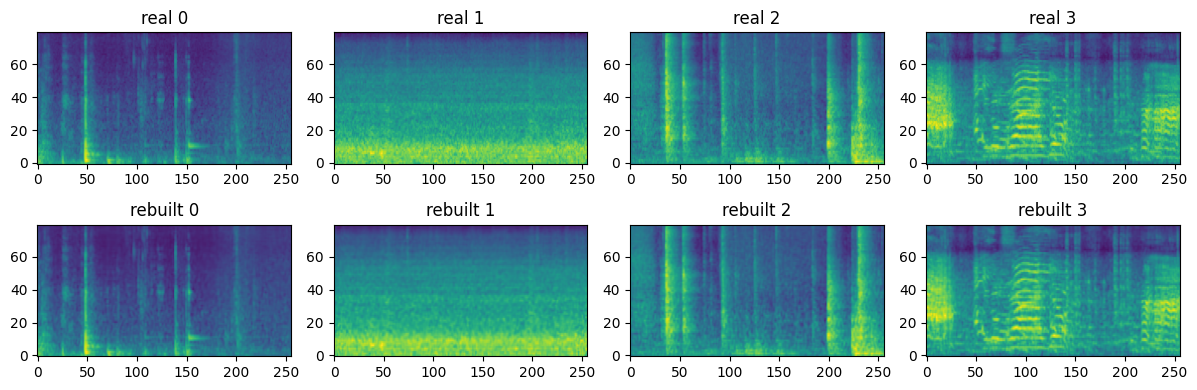

In [30]:
real, _ = next(iter(tiny_loader))
real = real[:4].to(device)

model.eval()
with torch.no_grad():
    out = model(real)[0].clamp(-1, 1)

fig, axes = plt.subplots(2, 4, figsize = (12, 4))
for i in range(4):
    axes[0, i].imshow(real[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[0, i].set_title(f"real {i}")
    axes[1, i].imshow(out[i].squeeze().cpu().numpy(), origin = "lower", aspect = "auto")
    axes[1, i].set_title(f"rebuilt {i}")
plt.tight_layout()
plt.show()

m = ((out + 1) / 2) * (MAX - MIN) + MIN
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

In [31]:
m_real = ((real + 1) / 2) * (MAX - MIN) + MIN
with torch.inference_mode():
    wav_real = vocoder(m_real.squeeze(1))
for i in range(4):
    display(Audio(wav_real[i].squeeze().cpu().numpy(), rate = 22050))

In [33]:
model.eval()
with torch.no_grad():
    mu_test, _ = model.encoder(real).chunk(2, dim = 1)
    out_mu = model.decoder(mu_test).clamp(-1, 1)
    out_z = model(real)[0].clamp(-1, 1)

print("L1, no noise:", F.l1_loss(out_mu, real).item())
print("L1, with noise:", F.l1_loss(out_z, real).item())

m = ((out_mu + 1) / 2) * (MAX - MIN) + MIN
with torch.inference_mode():
    wav = vocoder(m.squeeze(1))
for i in range(4):
    display(Audio(wav[i].squeeze().cpu().numpy(), rate = 22050))

L1, no noise: 0.017306683585047722
L1, with noise: 0.01731778495013714
